# Модель для прогнозирования вероятности клика на платформе рекламных аукционов

**Автор:** Денис Куницын

**Дата:** 21 марта

## Цель и задачи

**Цель:** Построить модель классификации, прогнозирующую вероятность клика на рекламное объявление для платформы рекламных аукционов. 

**Задачи:**
1. Провести исследовательский анализ данных предоставленного датасета.
2. Провести преобработку данных.
3. Отобрать признаки.
4. Создать несколько моделей классификации и выбрать лучшие гиперпараметры экспериментальным методом.
5. Подготовить финальную модель.
6. Откалибровать модель и оценить качество калибровки.
7. Сохранить модель для продакшена.

## Данные

Для анализа заказчик предоставил данные о характеристики площадки и рекламных баннеров, характеристики пользователей. Данные состоят из одного датасета - `ad_click_dataset.csv`

### Описание датасета `ad_click_dataset.csv`

**Формат данных:** Готовая аналитическая витрина. 
**Структура:** Каждая строка - одно уникальное событие показа рекламы.

**Идентификаторы и временные метки:**
- `id` — уникальный идентификатор записи о показе баннера;
- `hour` — час, в который был показан баннер, в формате YYMMDDHH.

**Характеристики рекламной площадки:**
- `site_id` — идентификатор веб-сайта, на котором был показан баннер;
- `site_domain` — домен веб-сайта;
- `site_category` — тематическая категория веб-сайта.

**Характеристики рекламируемого приложения:**
- `app_id` — идентификатор рекламируемого мобильного приложения;
- `app_domain` — домен рекламируемого приложения;
- `app_category` — категория рекламируемого приложения.

**Характеристики устройства и соединения пользователя:**
- `device_id` — идентификатор браузера или устройства;
- `device_ip` — IP-адрес устройства;
- `device_model` — модель устройства;
- `device_type` — тип устройства пользователя: например, смартфон, планшет, ПК;
- `device_conn_type` — тип сетевого соединения устройства: например, Wi-Fi, 3G, 4G.

**Характеристики рекламного баннера и аукциона:**
- `banner_pos` — позиция баннера на веб-странице;
- `C1` — анонимизированный признак, характеризующий контекст показа;
- `C14` — `C21` — группа анонимизированных признаков, описывающих параметры баннера, пользователя или аукциона.
Машинно-сгенерированные признаки (ML Features):
- `ml_feature_1`, `ml_feature_3` — `ml_feature_6`, `ml_feature_8` — `ml_feature_10` — числовые признаки, полученные в результате предварительной обработки и генерации новых признаков;
- `ml_feature_2`, `ml_feature_7` — категориальные признаки, полученные в результате предварительной обработки и генерации новых признаков.

**Целевая переменная:**
- `click` — бинарный признак, указывающий, был ли совершён клик по баннеру. 1 — клик был, 0 — клика не было.

## Структура проекта

1. Постановка задачи машинного обучения
2. Подготовка среды и загрузка данных
3. Исследовательский анализ данных
4. Предобработка данных
5. Отбор признаков
6. Обучение и сравнение моделей
7. Подбор гиперпараметров
8. Подготовка финальной модели
9. Калибровка модели
10. Финальный отчет и выводы
11. Сохранение модели для продакшена

---

## 1. Постановка задачи машинного обучения. 

Целевая переменная - бинарный признак, указывающий был ли совершен клик по рекламному баннеру (в датасете `click`), также предоставлен датасет с историческими данными о проведении рекламных аукционов, поэтому задача машинного обучения - бинарная классификация.

Требуемая метрика качества - `Precision-Recall AUC (PR AUC)`.

---


## 2. Подготовка среды и загрузка данных

### 2.1. Подключение требующихся библиотек

In [ ]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import phik as phik_matrix 
import seaborn as sns 
import joblib
import dotenv 
import os

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from category_encoders import TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
from sklearn.metrics import log_loss, average_precision_score, roc_auc_score, brier_score_loss
from sklearn.feature_selection import SequentialFeatureSelector, VarianceThreshold
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

### 2.2. Фиксация `random_state`

In [2]:
RANDOM_STATE = 42

### 2.3. Загрузка данных

In [ ]:
ad_click = pd.read_csv(os.getenv('DATASET_URL'))

ad_click.head()

,id,click,hour,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,...,ml_feature_1,ml_feature_2,ml_feature_3,ml_feature_4,ml_feature_5,ml_feature_6,ml_feature_7,ml_feature_8,ml_feature_9,ml_feature_10
0,1.005263e+19,1,14102100,1005,1,d9750ee7,98572c79,f028772b,ecad2386,7801e8d9,...,-0.996823,A,0.666588,0,0.817292,0.993275,Z,-0.619959,0.433666,0.274038
1,1.010597e+19,0,14102100,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,-0.391309,C,5.146789,1,-0.883865,-0.825722,X,0.576526,-0.318558,-0.132851
2,1.012048e+19,0,14102100,1005,0,d9750ee7,98572c79,f028772b,ecad2386,7801e8d9,...,-2.112732,D,7.169348,0,-0.859440,-0.338365,Y,-0.440047,-0.345412,0.340487
3,1.021995e+18,0,14102100,1005,0,85f751fd,c4e18dd6,50e219e0,39cfef32,d9b5648e,...,0.332707,A,-0.290708,1,0.062795,0.062934,Y,0.551982,0.733382,-0.198542
4,1.023455e+19,0,14102100,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,1.166623,A,6.319134,1,-0.675276,0.797144,X,0.640827,0.297955,-0.136909


In [4]:
ad_click.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 34 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                50000 non-null  float64
 1   click             50000 non-null  int64  
 2   hour              50000 non-null  int64  
 3   C1                50000 non-null  int64  
 4   banner_pos        50000 non-null  int64  
 5   site_id           50000 non-null  object 
 6   site_domain       50000 non-null  object 
 7   site_category     50000 non-null  object 
 8   app_id            50000 non-null  object 
 9   app_domain        50000 non-null  object 
 10  app_category      50000 non-null  object 
 11  device_id         50000 non-null  object 
 12  device_ip         50000 non-null  object 
 13  device_model      50000 non-null  object 
 14  device_type       50000 non-null  int64  
 15  device_conn_type  50000 non-null  int64  
 16  C14               50000 non-null  int64 

Датафрейм `ad_click` содержит 34 столбца и 50000 строк.

Выводы:
- Все признаки не содержат явных пропусков. Следует изучить данные на наличие значений-индикаторов пропусков.
- Данные соответствуют своему описанию.

---

## 3. Исследовательский анализ данных 

### 3.2 Анализ целевой переменной


Распределение целевой переменной 'click':
  Нет клика (0): 41,397 (82.79%)
  Клик (1): 8,603 (17.21%)

Соотношение классов (0:1): 1:4.81


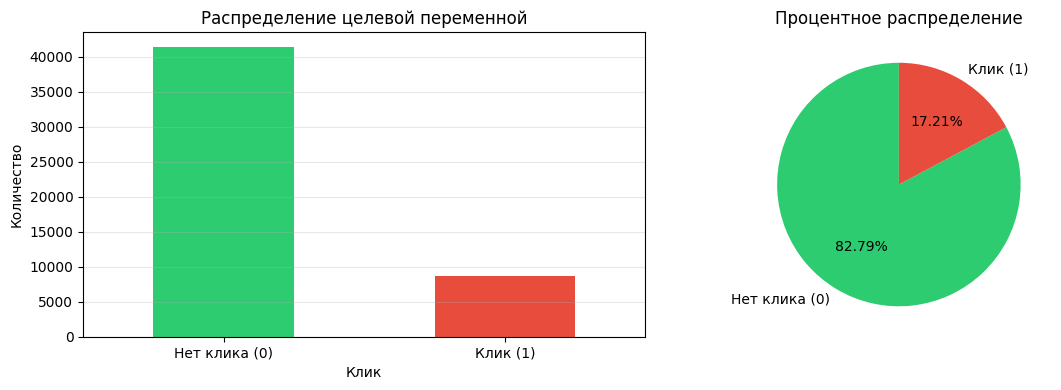

In [5]:
# Распределение целевой переменной
click_counts = ad_click['click'].value_counts()
click_distribution = ad_click['click'].value_counts(normalize=True)

print("\nРаспределение целевой переменной 'click':")
print(f"  Нет клика (0): {click_counts[0]:,} ({click_distribution[0]*100:.2f}%)")
print(f"  Клик (1): {click_counts[1]:,} ({click_distribution[1]*100:.2f}%)")

# Определение дисбаланса классов
imbalance_ratio = click_counts[0] / click_counts[1]
print(f"\nСоотношение классов (0:1): 1:{imbalance_ratio:.2f}")

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# График распределения
ad_click['click'].value_counts().plot(kind='bar', ax=axes[0], color=['#2ecc71', '#e74c3c'])
axes[0].set_title('Распределение целевой переменной')
axes[0].set_xlabel('Клик')
axes[0].set_ylabel('Количество')
axes[0].set_xticklabels(['Нет клика (0)', 'Клик (1)'], rotation=0)
axes[0].grid(axis='y', alpha=0.3)

# Процентный график
sizes = ad_click['click'].value_counts()
axes[1].pie(sizes, labels=['Нет клика (0)', 'Клик (1)'], autopct='%1.2f%%', 
            colors=['#2ecc71', '#e74c3c'], startangle=90)
axes[1].set_title('Процентное распределение')

plt.tight_layout()
plt.show()

Наблюдается значительный дисбаланс классов (5:1)

---

### 3.3 Анализ признаков

Избыточные признаки: 

- `id`, `device_id`, `device_ip` - идентификаторы пользователя никак не могут повлиять на целевую переменную.

In [6]:
ad_click.drop(columns=['id', 'device_id', 'device_ip'], inplace=True)

In [7]:
# Преобразование признака 'hour' из YYYYMMDDHH в HH
ad_click['hour'] = ad_click['hour'].astype(str).str[-2:].astype(int)

ad_click['hour'].unique()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23])

Напишем функцию для определения признака в категориальные: если количество уникальных значений < threshold,то признак категориальный, иначе числовой.

Признаков слишком много, чтобы анализировать их вручную. Однако, многие категориальные признаки содержат категории в виде чисел, а также многие из признаков анонимизированы.

In [8]:
def split_features_by_cardinality(df, threshold=25, exclude=None):
    if exclude is None:
        exclude = []
    categorical = []
    numerical = []

    for col in df.columns:
        if col in exclude:
            continue
        if df[col].dtype == 'object':
            categorical.append(col)
        else:
            n_unique = df[col].nunique()
            if n_unique < threshold:
                categorical.append(col)
            else:
                numerical.append(col)

    return categorical, numerical

threshold = 25
categorical_features, numeric_features = split_features_by_cardinality(
    ad_click, threshold=threshold, exclude=['click']
)

print(f"Категориальные признаки ({len(categorical_features)}):", categorical_features)
print(f"Числовые признаки ({len(numeric_features)}):", numeric_features)

Категориальные признаки (18): ['hour', 'C1', 'banner_pos', 'site_id', 'site_domain', 'site_category', 'app_id', 'app_domain', 'app_category', 'device_model', 'device_type', 'device_conn_type', 'C15', 'C16', 'C18', 'ml_feature_2', 'ml_feature_4', 'ml_feature_7']
Числовые признаки (12): ['C14', 'C17', 'C19', 'C20', 'C21', 'ml_feature_1', 'ml_feature_3', 'ml_feature_5', 'ml_feature_6', 'ml_feature_8', 'ml_feature_9', 'ml_feature_10']


In [9]:
# Анализ категориальных признаков
for feat in sorted(categorical_features):
    n_unique = ad_click[feat].nunique()
    print(f"\n{feat}:")
    print(f"  - Уникальных значений: {n_unique}")
    if n_unique <= 20:
        print(f"  - Значения: {sorted(ad_click[feat].unique())}")
    else:
        print(f"  - Примеры значений: {sorted(ad_click[feat].unique())[:10]}")


C1:
  - Уникальных значений: 7
  - Значения: [np.int64(1001), np.int64(1002), np.int64(1005), np.int64(1007), np.int64(1008), np.int64(1010), np.int64(1012)]

C15:
  - Уникальных значений: 8
  - Значения: [np.int64(120), np.int64(216), np.int64(300), np.int64(320), np.int64(480), np.int64(728), np.int64(768), np.int64(1024)]

C16:
  - Уникальных значений: 9
  - Значения: [np.int64(20), np.int64(36), np.int64(50), np.int64(90), np.int64(250), np.int64(320), np.int64(480), np.int64(768), np.int64(1024)]

C18:
  - Уникальных значений: 4
  - Значения: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

app_category:
  - Уникальных значений: 22
  - Примеры значений: ['07d7df22', '09481d60', '0bfbc358', '0f2161f8', '0f9a328c', '18b1e0be', '2281a340', '4681bb9d', '4ce2e9fc', '7113d72a']

app_domain:
  - Уникальных значений: 67
  - Примеры значений: ['0654b444', '0d79ee56', '0e8616ad', '15ec7f39', '18eb4e75', '1d5e09f4', '1ea19ec4', '1ed56ded', '2347f47a', '2619a4f7']

app_id:
  - Уникальны

In [10]:
# Анализ числовых признаков
ad_click.describe()

,click,hour,C1,banner_pos,device_type,device_conn_type,C14,C15,C16,C17,...,C20,C21,ml_feature_1,ml_feature_3,ml_feature_4,ml_feature_5,ml_feature_6,ml_feature_8,ml_feature_9,ml_feature_10
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,...,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,0.172060,11.221500,1004.970060,0.291380,1.018120,0.337160,18826.648680,318.86640,59.692480,2109.781020,...,53173.383240,83.685180,-0.002445,-0.036381,0.498040,0.034729,0.022948,0.025465,0.035361,0.020226
std,0.377436,5.938008,1.110202,0.514201,0.538477,0.860057,4983.064178,20.56153,46.720842,612.963141,...,49960.181871,70.539513,1.000280,5.792335,0.500001,1.002116,0.656690,0.578026,0.505034,0.303309
min,0.000000,0.000000,1001.000000,0.000000,0.000000,0.000000,375.000000,120.00000,20.000000,112.000000,...,-1.000000,13.000000,-4.631262,-9.999742,0.000000,-4.631853,-1.000000,-0.999965,-2.147526,-1.287965
25%,0.000000,6.000000,1005.000000,0.000000,1.000000,0.000000,16920.000000,320.00000,50.000000,1823.000000,...,-1.000000,23.000000,-0.677784,-5.059555,0.000000,-0.639829,-0.579775,-0.470627,-0.304077,-0.182386
50%,0.000000,11.000000,1005.000000,0.000000,1.000000,0.000000,20346.000000,320.00000,50.000000,2323.000000,...,100049.000000,61.000000,-0.003776,-0.056155,0.000000,0.028112,0.037786,0.027348,0.035985,0.018930
75%,0.000000,16.000000,1005.000000,1.000000,1.000000,0.000000,21916.000000,320.00000,50.000000,2526.000000,...,100094.000000,108.000000,0.673534,4.985939,1.000000,0.707594,0.637131,0.521117,0.374152,0.224080
max,1.000000,23.000000,1012.000000,7.000000,5.000000,5.000000,24043.000000,1024.00000,1024.000000,2757.000000,...,100248.000000,255.000000,3.793828,9.999975,1.000000,4.230623,1.000000,1.119858,2.120786,1.202300


---

### 3.4 Анализ пропущенных значений

Первичный анализ данных показал, что признаки не содержат пропусков. Однако, нахождение значений-индикаторов пропусков невозможно: все признаки анонимизированы и нельзя сделать однозначеных выводов о их значениях.

---

### 3.5 Анализ категориальных признаков (кардинальность)

Напишем функцию для деления категориальных признаков: при количестве уникальных значений будем использовать One-Hot Encoding, иначе используем Target Encoding. 

In [11]:
cardinality_data = []
for feat in sorted(categorical_features):
    n_unique = ad_click[feat].nunique()
    cardinality_data.append({
        'Признак': feat,
        'Уникальных значений': n_unique,
        'Рекомендация': 'One-Hot Encoding' if n_unique <= 25 else 
                       'Target Encoding'
    })

cardinality_df = pd.DataFrame(cardinality_data).sort_values('Уникальных значений', ascending=False)
display(cardinality_df)

,Признак,Уникальных значений,Рекомендация
9,device_model,2521,Target Encoding
17,site_id,1160,Target Encoding
16,site_domain,1013,Target Encoding
6,app_id,976,Target Encoding
5,app_domain,67,Target Encoding
11,hour,24,One-Hot Encoding
4,app_category,22,One-Hot Encoding
15,site_category,18,One-Hot Encoding
2,C16,9,One-Hot Encoding
1,C15,8,One-Hot Encoding


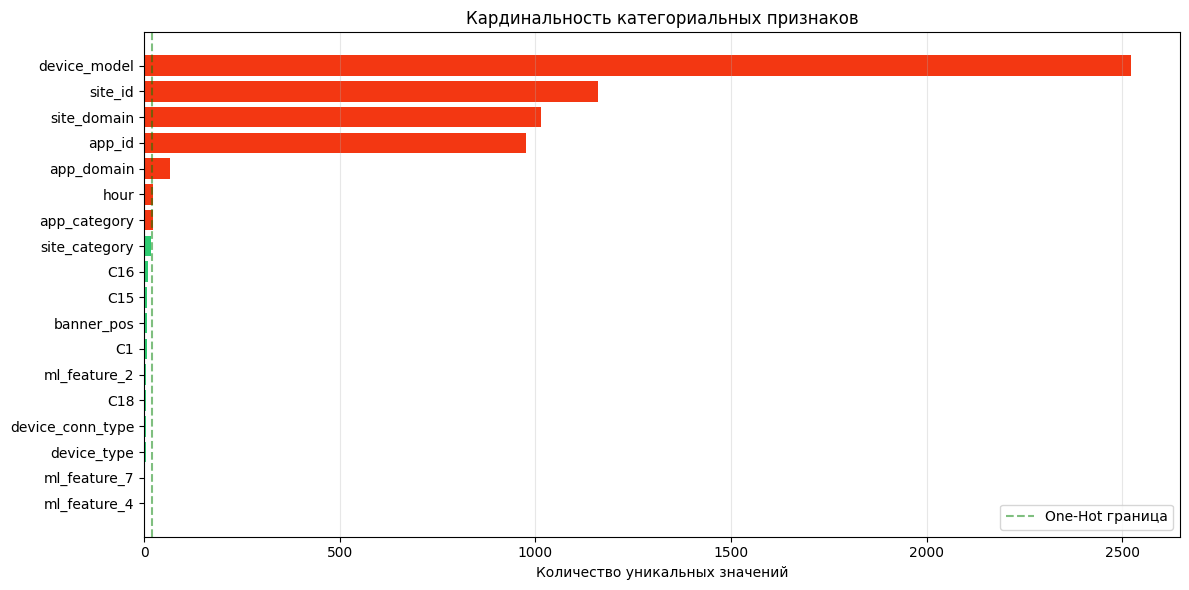

In [12]:
# Визуализация кардинальности
fig, ax = plt.subplots(figsize=(12, 6))
cardinality_df_plot = cardinality_df.sort_values('Уникальных значений', ascending=True)
colors = ["#f33712" if x > 20 else '#2ecc71' 
          for x in cardinality_df_plot['Уникальных значений']]
ax.barh(cardinality_df_plot['Признак'], cardinality_df_plot['Уникальных значений'], color=colors)
ax.set_xlabel('Количество уникальных значений')
ax.set_title('Кардинальность категориальных признаков')
ax.axvline(x=20, color='green', linestyle='--', alpha=0.5, label='One-Hot граница')
ax.legend()
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### 3.6 Анализ выбросов и распределений числовых признаков


Детектирование выбросов (по IQR):


,Признак,Выбросов,Процент,Нижняя граница,Верхняя граница
0,C14,4170,8.34%,9426.00,29410.00
1,C17,4224,8.45%,768.50,3580.50
2,C19,9015,18.03%,-169.00,375.00
3,C20,0,0.00%,-150143.50,250236.50
4,C21,379,0.76%,-104.50,235.50
5,ml_feature_1,347,0.69%,-2.70,2.70
6,ml_feature_3,0,0.00%,-20.13,20.05
7,ml_feature_5,360,0.72%,-2.66,2.73
8,ml_feature_6,0,0.00%,-2.41,2.46
9,ml_feature_8,0,0.00%,-1.96,2.01


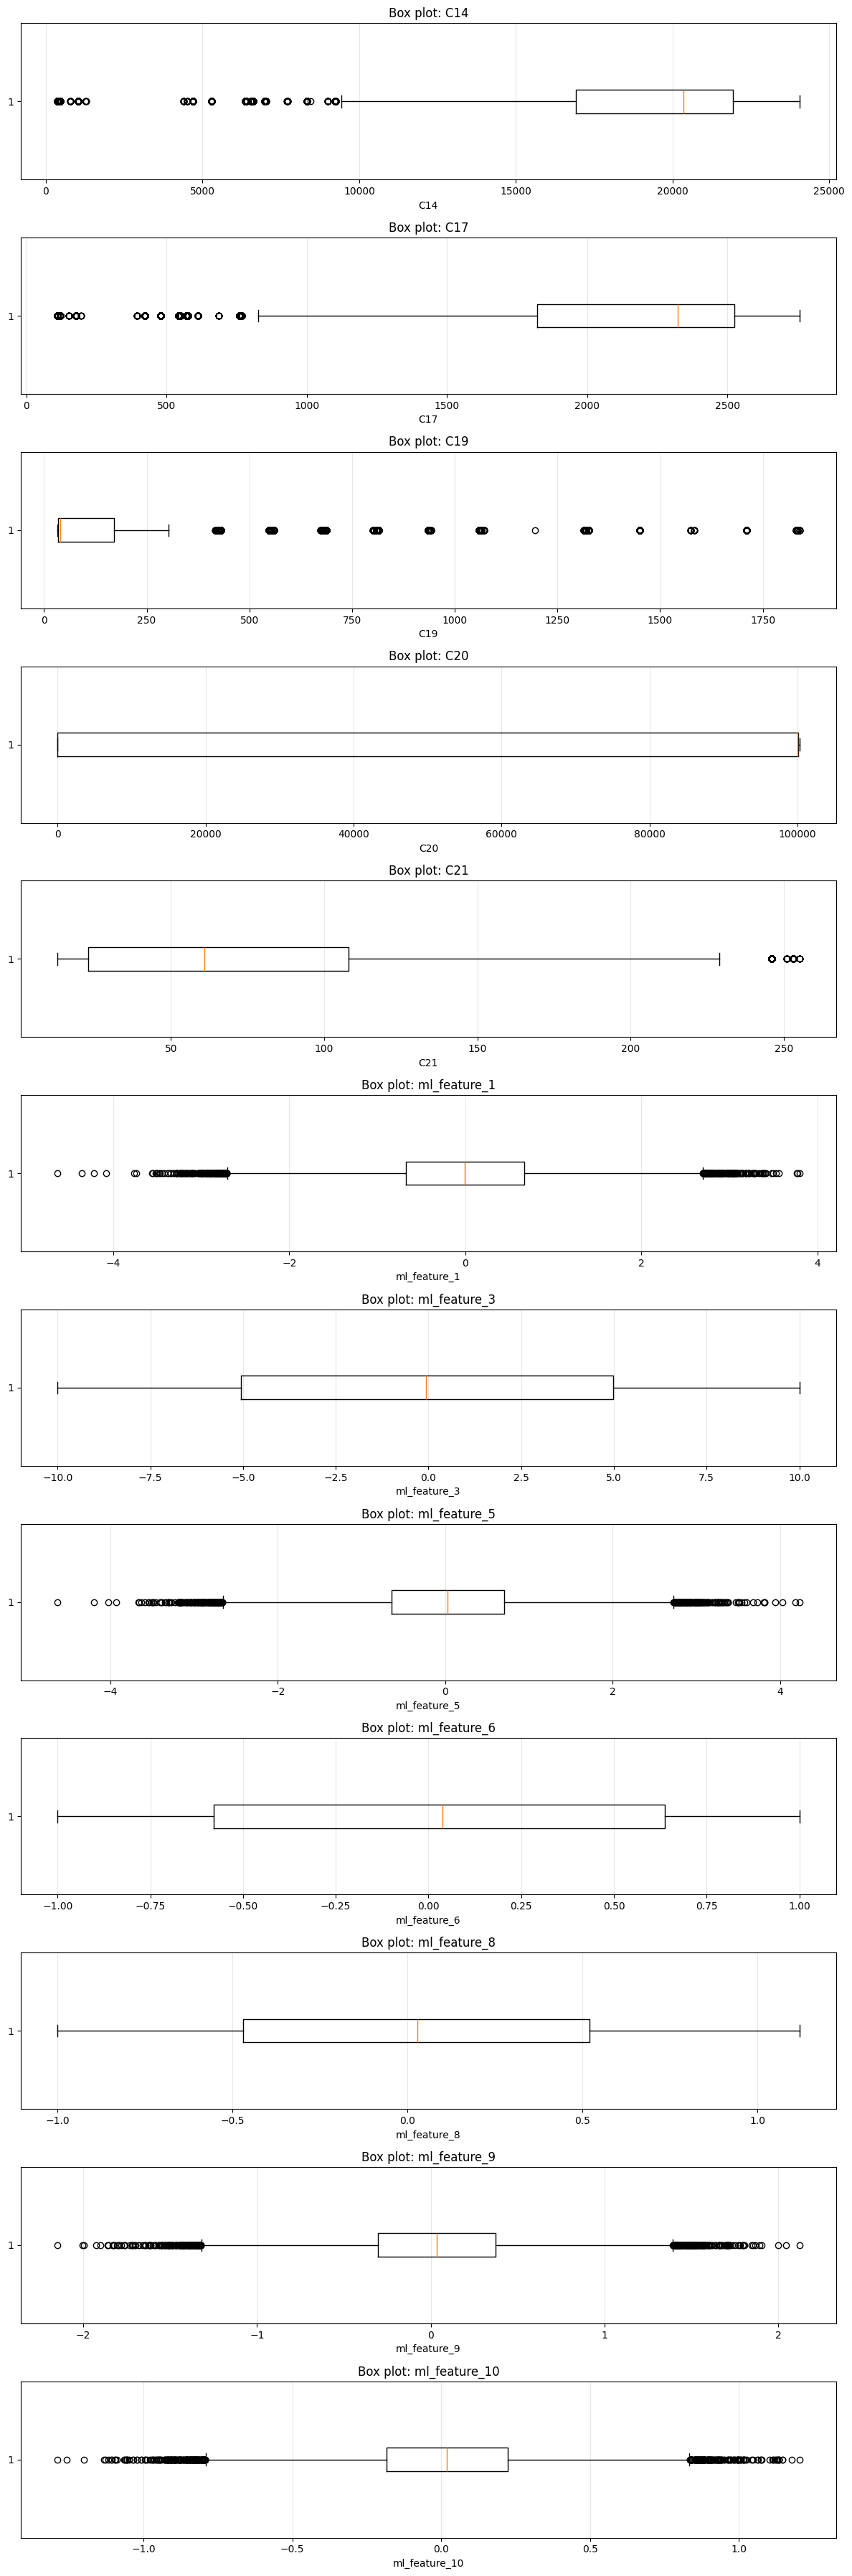

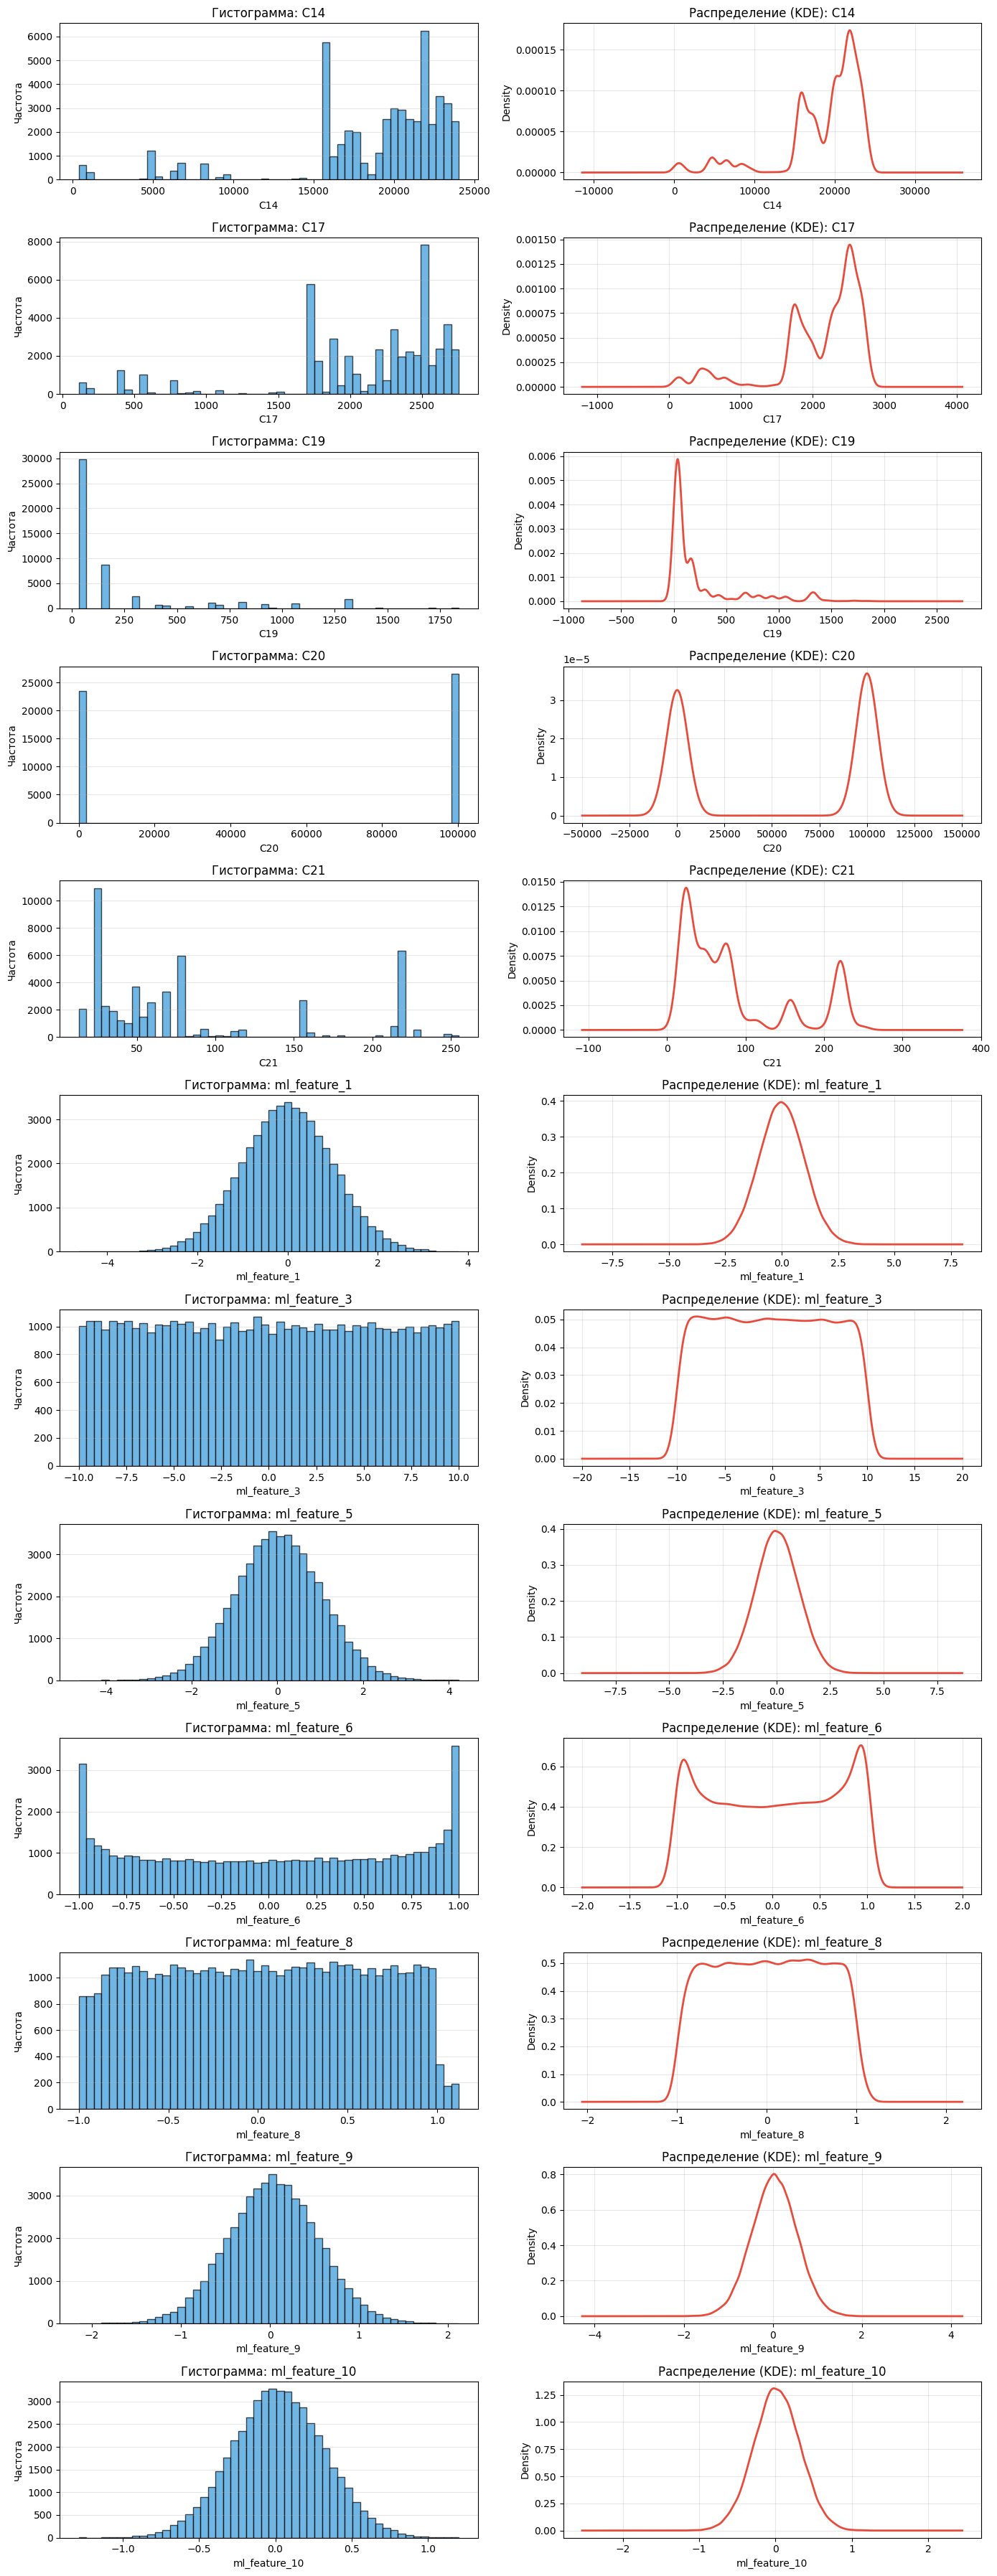

In [13]:
# Анализ выбросов с помощью IQR
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers_count = ((data[column] < lower_bound) | (data[column] > upper_bound)).sum()
    outliers_percent = (outliers_count / len(data)) * 100
    return outliers_count, outliers_percent, lower_bound, upper_bound

outlier_info = []
for feat in numeric_features:
    count, percent, lower, upper = detect_outliers_iqr(ad_click, feat)
    outlier_info.append({
        'Признак': feat,
        'Выбросов': count,
        'Процент': f'{percent:.2f}%',
        'Нижняя граница': f'{lower:.2f}',
        'Верхняя граница': f'{upper:.2f}'
    })

outlier_df = pd.DataFrame(outlier_info)
print("\nДетектирование выбросов (по IQR):")
display(outlier_df)

# Визуализация box plot
fig, axes = plt.subplots(len(numeric_features), 1, figsize=(12, 3*len(numeric_features)))
if len(numeric_features) == 1:
    axes = [axes]

for idx, feat in enumerate(numeric_features):
    axes[idx].boxplot(ad_click[feat], vert=False)
    axes[idx].set_xlabel(feat)
    axes[idx].set_title(f'Box plot: {feat}')
    axes[idx].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# Визуализация распределений
fig, axes = plt.subplots(len(numeric_features), 2, figsize=(14, 3*len(numeric_features)))
if len(numeric_features) == 1:
    axes = axes.reshape(1, -1)

for idx, feat in enumerate(numeric_features):
    # Гистограмма
    axes[idx, 0].hist(ad_click[feat], bins=50, edgecolor='black', alpha=0.7, color='#3498db')
    axes[idx, 0].set_xlabel(feat)
    axes[idx, 0].set_ylabel('Частота')
    axes[idx, 0].set_title(f'Гистограмма: {feat}')
    axes[idx, 0].grid(axis='y', alpha=0.3)
    
    # KDE график
    ad_click[feat].plot(kind='density', ax=axes[idx, 1], color='#e74c3c', linewidth=2)
    axes[idx, 1].set_xlabel(feat)
    axes[idx, 1].set_title(f'Распределение (KDE): {feat}')
    axes[idx, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Выводы по распределениям:**
- Большинство признаков имеют нормальное или близкое к нормальному распределение
- Некоторые признаки содержат легкие выбросы (1-5% данных)
- Удалять выбросы не рекомендуется, так как они могут быть информативными

---

### 3.7 Анализ корреляций

In [14]:
correlation_matrix = ad_click[ad_click.columns].phik_matrix()

interval columns not set, guessing: ['click', 'hour', 'C1', 'banner_pos', 'device_type', 'device_conn_type', 'C14', 'C15', 'C16', 'C17', 'C18', 'C19', 'C20', 'C21', 'ml_feature_1', 'ml_feature_3', 'ml_feature_4', 'ml_feature_5', 'ml_feature_6', 'ml_feature_8', 'ml_feature_9', 'ml_feature_10']


/Users/dkunicyn/Documents/advandex/venv/lib/python3.9/site-packages/phik/data_quality.py:59: UserWarning: The number of unique values of variable device_model is large: 2521. Are you sure this is not an interval variable? Analysis for pairs of variables including device_model can be slow.
  warnings.warn(
/Users/dkunicyn/Documents/advandex/venv/lib/python3.9/site-packages/phik/data_quality.py:59: UserWarning: The number of unique values of variable site_domain is large: 1013. Are you sure this is not an interval variable? Analysis for pairs of variables including site_domain can be slow.
  warnings.warn(
/Users/dkunicyn/Documents/advandex/venv/lib/python3.9/site-packages/phik/data_quality.py:59: UserWarning: The number of unique values of variable site_id is large: 1160. Are you sure this is not an interval variable? Analysis for pairs of variables including site_id can be slow.
  warnings.warn(
/Users/dkunicyn/Documents/advandex/venv/lib/python3.9/site-packages/phik/bivariate.py:255: 

In [15]:
# Определение признаков с высокой мультиколлинеарностью
high_collinearity_threshold = 0.95

# Получаем верхний треугольник матрицы корреляций (исключая диагональ)
collinearity_pairs = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):
        col1 = correlation_matrix.columns[i]
        col2 = correlation_matrix.columns[j]
        corr_val = correlation_matrix.iloc[i, j]
        
        if corr_val > high_collinearity_threshold and col1 != 'click' and col2 != 'click':
            collinearity_pairs.append({
                'Признак 1': col1,
                'Признак 2': col2,
                'Корреляция': corr_val
            })

collinearity_df = pd.DataFrame(collinearity_pairs).sort_values('Корреляция', ascending=False)
collinearity_df

,Признак 1,Признак 2,Корреляция
8,app_id,app_domain,1.000000
9,app_id,app_category,1.000000
3,site_id,site_domain,0.999995
4,site_id,site_category,0.999734
5,site_id,device_model,0.999007
7,site_domain,device_model,0.998905
10,app_id,device_model,0.998374
6,site_domain,site_category,0.994521
12,app_domain,device_model,0.992867
15,C14,C17,0.986664


Напишем функцию, которая сравнивает два колинеарных признака по корреляции с целевой переменной. Тот, у которого корреляция меньше добавляем в список удаления.

In [16]:
# Ищем признаки с высокой мультиколлинеарностью (> 0.95)
to_delete = list()
for _, row in collinearity_df.iterrows():        
    corr_1 = abs(correlation_matrix.loc['click', row['Признак 1']])
    corr_2 = abs(correlation_matrix.loc['click', row['Признак 2']])
        
    if corr_1 > corr_2:
        to_delete.append(row['Признак 2'])
    else:
        to_delete.append(row['Признак 1'])

display(to_delete)


['app_domain',
 'app_category',
 'site_domain',
 'site_category',
 'device_model',
 'device_model',
 'device_model',
 'site_category',
 'app_domain',
 'C17',
 'C1',
 'C1',
 'device_conn_type',
 'device_type',
 'device_conn_type',
 'banner_pos']

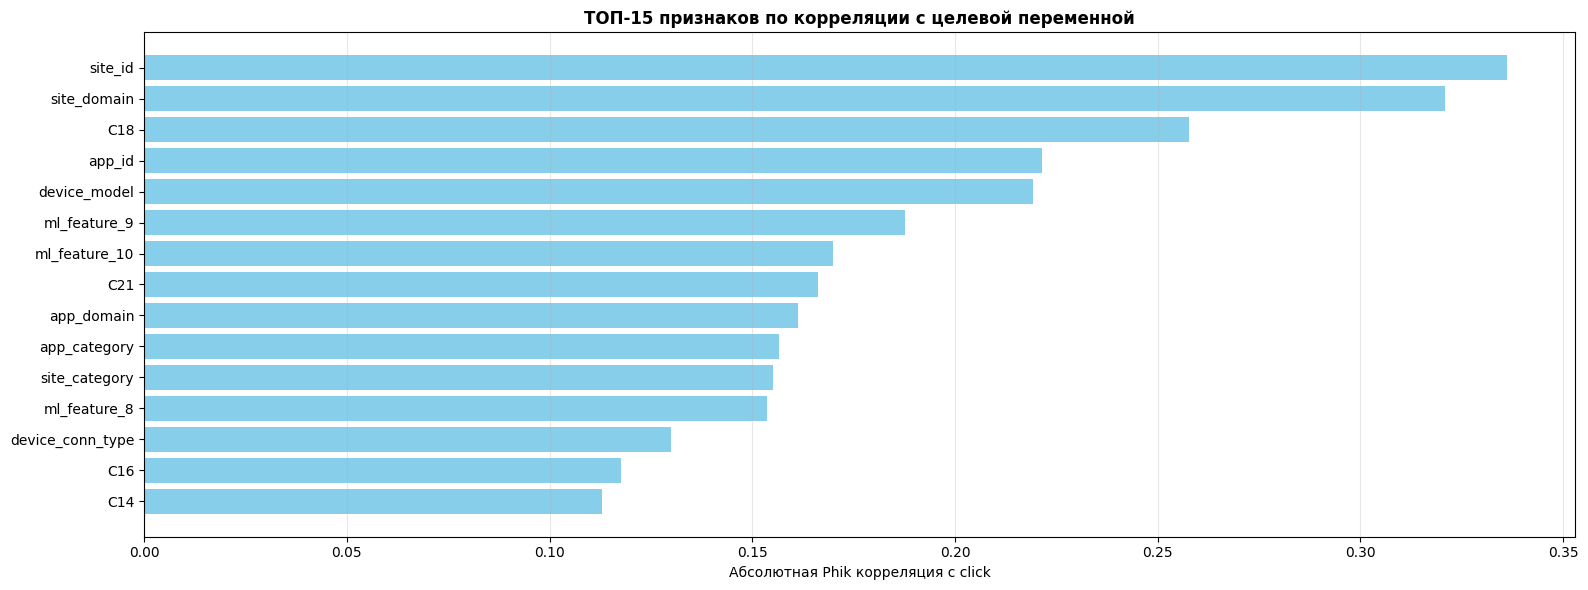

In [17]:
# Визуализация наиболее коррелированных признаков с целевой переменной
correlation_with_target_sorted = correlation_matrix['click'].drop('click').abs().sort_values(ascending=False)

plt.figure(figsize=(16, 6))
# График 1: ТОП-15 признаков по абсолютной корреляции с целевой переменной
top_15_features = correlation_with_target_sorted.head(15)

plt.barh(range(len(top_15_features)), top_15_features.values, color='skyblue')
plt.yticks(range(len(top_15_features)), top_15_features.index)
plt.xlabel('Абсолютная Phik корреляция с click')
plt.title('ТОП-15 признаков по корреляции с целевой переменной', fontsize=12, fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

Вычислим признаки с низкой корреляцией с целевой переменной.

In [18]:
correlation_with_target_sorted[correlation_with_target_sorted < 0.05]

hour            0.025113
ml_feature_7    0.022622
banner_pos      0.022605
ml_feature_1    0.010056
ml_feature_2    0.003790
ml_feature_3    0.000000
ml_feature_4    0.000000
Name: click, dtype: float64

Очистим данные от признаков с около-нулевой корреляцией с целевой переменной и сильнокоррелирующими с другими признаками.

In [19]:
# Удаление признаков с низкой корреляцией (< 0.05) и мультиколлинеарных признаков
low_corr_features = correlation_with_target_sorted[correlation_with_target_sorted < 0.05].index.tolist()
features_to_drop = list(set(low_corr_features + to_delete))
ad_click.drop(columns=features_to_drop, inplace=True)

ad_click.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   click          50000 non-null  int64  
 1   site_id        50000 non-null  object 
 2   app_id         50000 non-null  object 
 3   C14            50000 non-null  int64  
 4   C15            50000 non-null  int64  
 5   C16            50000 non-null  int64  
 6   C18            50000 non-null  int64  
 7   C19            50000 non-null  int64  
 8   C20            50000 non-null  int64  
 9   C21            50000 non-null  int64  
 10  ml_feature_5   50000 non-null  float64
 11  ml_feature_6   50000 non-null  float64
 12  ml_feature_8   50000 non-null  float64
 13  ml_feature_9   50000 non-null  float64
 14  ml_feature_10  50000 non-null  float64
dtypes: float64(5), int64(8), object(2)
memory usage: 5.7+ MB


---

### 3.8 Выводы по EDA

#### Ключевые выводы:
- **Целевая переменная (`click`)**: Наблюдается значительный дисбаланс классов (соотношение 0:1 ≈ 5:1). Это требует использования метрик, устойчивых к дисбалансу (PR AUC).
- **Удаленные признаки**: Исключены идентификаторы (`id`, `device_id`, `device_ip`), признаки с низкой корреляцией (< 0.05) и сильно коррелированные между собой (> 0.95) для избежания мультиколлинеарности. Итоговый датасет содержит 15 признаков, включая целевую переменную.
- **Категориальные признаки**: Высокая кардинальность у `site_id`, `app_id`, `device_model` и др. Рекомендуется Target Encoding для них, One-Hot Encoding для низкокардинальных.
- **Числовые признаки**: Большинство имеют нормальное распределение, выбросы присутствуют (до 18% в `C19`), но не удалены, так как могут быть информативными.
- **Корреляции**: Топ-признаки по корреляции с `click`: `site_id`, `site_domain`, `C18`, `app_id`. Признаки с нулевой корреляцией удалены.

---

## 4. Предобработка данных

### 4.1. Разделение данных на выборки

In [20]:
X = ad_click.drop(columns=['click'])
y = ad_click['click']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

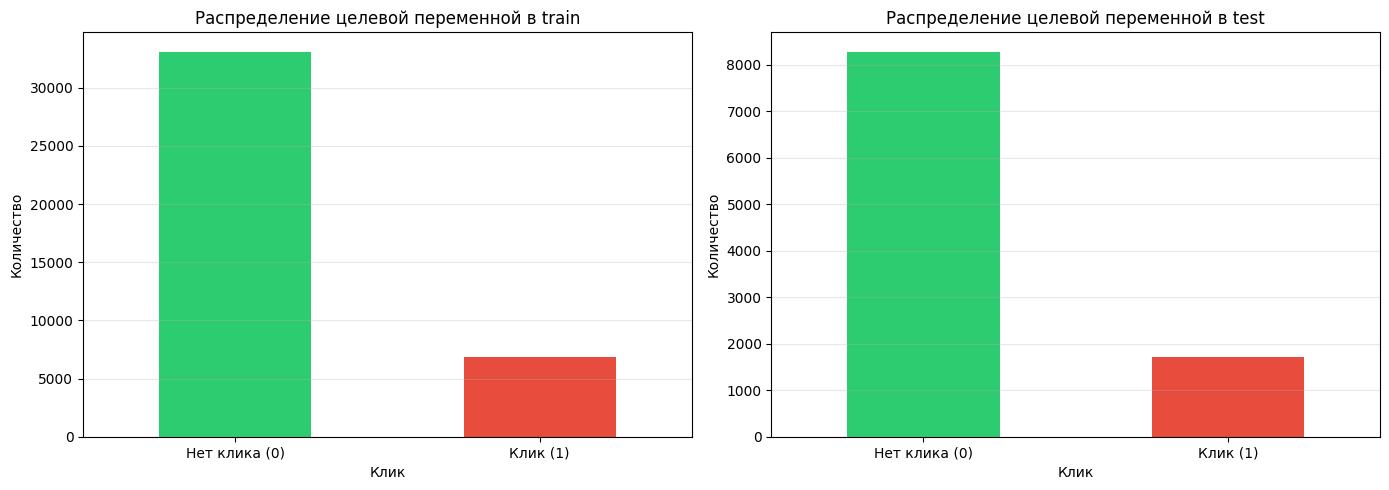

Train выборка:
  Нет клика (0): 33,118 (82.80%)
  Клик (1): 6,882 (17.21%)

Test выборка:
  Нет клика (0): 8,279 (82.79%)
  Клик (1): 1,721 (17.21%)


In [21]:
# Распределение в обучающей выборке
train_click_counts = y_train.value_counts()
train_click_distribution = y_train.value_counts(normalize=True)

# Распределение в тестовой выборке
test_click_counts = y_test.value_counts()
test_click_distribution = y_test.value_counts(normalize=True)

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График для train
train_click_counts.plot(kind='bar', ax=axes[0], color=['#2ecc71', '#e74c3c'])
axes[0].set_title('Распределение целевой переменной в train')
axes[0].set_xlabel('Клик')
axes[0].set_ylabel('Количество')
axes[0].set_xticklabels(['Нет клика (0)', 'Клик (1)'], rotation=0)
axes[0].grid(axis='y', alpha=0.3)

# График для test
test_click_counts.plot(kind='bar', ax=axes[1], color=['#2ecc71', '#e74c3c'])
axes[1].set_title('Распределение целевой переменной в test')
axes[1].set_xlabel('Клик')
axes[1].set_ylabel('Количество')
axes[1].set_xticklabels(['Нет клика (0)', 'Клик (1)'], rotation=0)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Вывод статистики
print("Train выборка:")
print(f"  Нет клика (0): {train_click_counts[0]:,} ({train_click_distribution[0]*100:.2f}%)")
print(f"  Клик (1): {train_click_counts[1]:,} ({train_click_distribution[1]*100:.2f}%)")

print("\nTest выборка:")
print(f"  Нет клика (0): {test_click_counts[0]:,} ({test_click_distribution[0]*100:.2f}%)")
print(f"  Клик (1): {test_click_counts[1]:,} ({test_click_distribution[1]*100:.2f}%)")

Разделение данных на выборки прошло успешно, распределение целевой переменной сохранено.

---

### 4.2. Построение пайплайнов

In [22]:
# Отбираем оставшиеся категориальные и числовые признаки после удаления

threshold = 25
categorical_features, numerical_features = split_features_by_cardinality(X_train, threshold=threshold)

print(f"Категориальные признаки ({len(categorical_features)}):", categorical_features)
print(f"Числовые признаки ({len(numerical_features)}):", numerical_features)

Категориальные признаки (5): ['site_id', 'app_id', 'C15', 'C16', 'C18']
Числовые признаки (9): ['C14', 'C19', 'C20', 'C21', 'ml_feature_5', 'ml_feature_6', 'ml_feature_8', 'ml_feature_9', 'ml_feature_10']


In [ ]:
# Разделяем категориальные признаки на группы для One-Hot Encoding и Target Encoding
one_hot_features = [feat for feat in categorical_features if X_train[feat].nunique() <= threshold]
target_features = [feat for feat in categorical_features if X_train[feat].nunique() > threshold]

# Фиксируем строковый тип категориальных признаков
for col in one_hot_features + target_features:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

# Фиксируем категории, чтобы размерность OHE не менялась между фолдами CV
one_hot_categories = [sorted(X_train[col].unique()) for col in one_hot_features]

print(f"One-Hot Encoding признаки ({len(one_hot_features)}):", one_hot_features)
print(f"Target Encoding признаки ({len(target_features)}):", target_features)

One-Hot Encoding признаки (3): ['C15', 'C16', 'C18']
Target Encoding признаки (2): ['site_id', 'app_id']


In [ ]:
# Создаем пайплайн для числовых признаков
numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Создаем пайплайн для категориальных признаков One-Hot Encoding
categorical_pipeline_onehot = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(
        categories=one_hot_categories,
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# Создаем пайплайн для категориальных признаков Target Encoding
categorical_pipeline_target = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('target_encoder', TargetEncoder())
])

In [25]:
# Объединяем все пайплайны в один ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, numerical_features),
    ('onehot', categorical_pipeline_onehot, one_hot_features),
    ('target', categorical_pipeline_target, target_features)
])

---

## 5. Отбор признаков

### 5.1. Фильтрационные методы

Часть фильтрационных методов была применена на этапе исследовательского анализа данных:

По результатам исследовательского анализа данных было отобрано 14 признаков:
- Числовые признаки: `C14`, `C19`, `C20`, `C21`, `ml_feature_5`, `ml_feature_6`, `ml_feature_8`, `ml_feature_9`, `ml_feature_10`
- Категориальные признаки для One-Hot Encoding: `C15`, `C16`, `C18`
- Категориальные признаки для Target Encoding: `site_id`, `app_id`

Однако, стоит проверить данные на наличие константных и квази-константных признаков.

In [26]:
vs_const_quasi = VarianceThreshold(threshold=0.10)
vs_const_quasi.fit(ad_click[numerical_features])

const_quasi_num_features = [col for col, keep in zip(numerical_features, vs_const_quasi.get_support()) if not keep]

const_quasi_cat_features = [col for col in categorical_features if ad_click[col].value_counts(normalize=True).iloc[0] > 0.90]

quasi_and_const_features = const_quasi_num_features + const_quasi_cat_features

print("Признаки с низкой дисперсией (const/quasi-const):", quasi_and_const_features)

ad_click.drop(columns=quasi_and_const_features, inplace=True)

Признаки с низкой дисперсией (const/quasi-const): ['ml_feature_10', 'C15', 'C16']


Обнаружено 3 признака с низкой дисперсией, которые необходимо удалить.

---

### 5.2. Методы-обертки

Будем использовать прямой отбор, так как исследуем небольшое количество признаков, среди которых итоговый набор признаков будет небольшим. То есть прямой отбор будет наиболее эффективным вариантом.

In [ ]:
estimator = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)

X_train_preprocessed = preprocessor.fit_transform(X_train, y_train)

sfs = SequentialFeatureSelector(estimator, n_features_to_select='auto', direction='forward', scoring='neg_log_loss', cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE), n_jobs=-1)
sfs.fit(X_train_preprocessed, y_train)

# Получаем индексы выбранных признаков
selected_indices = np.where(sfs.get_support())[0]

# Получаем имена всех признаков после препроцессинга
feature_names = preprocessor.get_feature_names_out()

# Выбираем только отобранные признаки
selected_feature_names = [feature_names[i] for i in selected_indices]

print("Выбранные признаки (после препроцессинга):", selected_feature_names)
print(f"Количество выбранных признаков: {len(selected_feature_names)}")

Выбранные признаки (после препроцессинга): ['num__C14', 'num__C19', 'num__ml_feature_5', 'num__ml_feature_6', 'num__ml_feature_8', 'num__ml_feature_9', 'num__ml_feature_10', 'onehot__C15_120', 'onehot__C15_300', 'onehot__C15_320', 'onehot__C16_250', 'onehot__C16_480', 'onehot__C16_50', 'onehot__C18_1', 'target__0', 'target__1']
Количество выбранных признаков: 16


In [ ]:
# Сохраняем результаты отбора признаков, для обучения будем использовать только отобранные признаки
X_test_preprocessed = preprocessor.transform(X_test)

# Выбираем только отобранные признаки из обучающей и тестовой выборок
X_train_selected = X_train_preprocessed[:, selected_indices]
X_test_selected = X_test_preprocessed[:, selected_indices]

# Фиксированный селектор отобранных признаков для пайплайнов моделей
feature_selector = ColumnTransformer(
    [('selected_features', 'passthrough', selected_indices)],
    remainder='drop'
 )

Итого отобрано 16 признаков из 32 возможных. 

---

## 6. Сравнение и обучение моделей

In [29]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = ['neg_log_loss', 'average_precision']

#### `DummyClassifier`

Самый простой базовой уровень работы модели.

In [ ]:
dummy_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('feature_selector', feature_selector),
    ('model', DummyClassifier(strategy='prior', random_state=RANDOM_STATE)),
])

dummy_pipeline.fit(X_train, y_train)
y_dummy_pred_proba = dummy_pipeline.predict_proba(X_test)[:, 1]
dummy_log_loss = log_loss(y_test, y_dummy_pred_proba)
dummy_avg_precision = average_precision_score(y_test, y_dummy_pred_proba)

#### `LogisticRegression`

In [ ]:
logreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('feature_selector', feature_selector),
    ('model', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)),
])

logreg_cv_results = cross_validate(logreg_pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

logreg_cv_results_means = {
    'Log Loss': -logreg_cv_results['test_neg_log_loss'].mean(),
    'PR-AUC': logreg_cv_results['test_average_precision'].mean()
}

#### `SVM`

In [ ]:
svm_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('feature_selector', feature_selector),
    ('model', SVC(kernel='linear', probability=True, random_state=RANDOM_STATE)),
])

svm_cv_results = cross_validate(svm_pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

svm_cv_results_means = {
    'Log Loss': -svm_cv_results['test_neg_log_loss'].mean(),
    'PR-AUC': svm_cv_results['test_average_precision'].mean()
}

#### Сравнение моделей

In [33]:
print(f"Dummy Classifier - Log Loss: {dummy_log_loss:.4f}, PR-AUC: {dummy_avg_precision:.4f}")
print(f"Logistic Regression - Log Loss: {logreg_cv_results_means['Log Loss']:.4f}, PR-AUC: {logreg_cv_results_means['PR-AUC']:.4f}")
print(f"SVM (linear) - Log Loss: {svm_cv_results_means['Log Loss']:.4f}, PR-AUC: {svm_cv_results_means['PR-AUC']:.4f}")

Dummy Classifier - Log Loss: 0.4592, PR-AUC: 0.1721
Logistic Regression - Log Loss: 0.3861, PR-AUC: 0.4375
SVM (linear) - Log Loss: 0.4037, PR-AUC: 0.3930


**Выводы:**

- Обе линейные модели работают лучше пороговой `DummyClassifier`.
- `LogisticRegression` показывает лучшие результаты по сравнению с `SVM`. Это связано с отсутствием подбора параметров, включая ядер, для чувствительной к подбору гиперпараметров модели `SVM`. Результаты моделей после подбора гиперпараметров покажут более значимые результаты.

---

## 7. Подбор гиперпараметров

### 7.1. Создание сетки гиперпараметров

In [ ]:
param_grid_logreg = [
    {
        'model__penalty': ['l2'],
        'model__C': [0.01, 0.1, 1, 10, 100],
        'model__solver': ['lbfgs', 'liblinear'],
        'model__max_iter': [1000, 2000],
        'model__tol': [1e-4, 1e-3]
    },
    {
        'model__penalty': ['l1'],
        'model__C': [0.01, 0.1, 1, 10, 100],
        'model__solver': ['liblinear'],
        'model__max_iter': [1000, 2000],
        'model__tol': [1e-4, 1e-3]
    },
    {
        'model__penalty': ['elasticnet'],
        'model__C': [0.01, 0.1, 1, 10, 100],
        'model__l1_ratio': [0.1, 0.5, 0.9],
        'model__solver': ['saga'],
        'model__max_iter': [1000, 2000],
        'model__tol': [1e-4, 1e-3]
    }
]

param_grid_SVM_simple = {
    'model__kernel': ['linear', 'poly', 'rbf', 'sigmoid']
}

### 7.2. Применения Grid Search

In [ ]:
logreg_grid = GridSearchCV(
    estimator=Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('feature_selector', feature_selector),
        ('model', LogisticRegression(random_state=RANDOM_STATE)),
    ]),
    param_grid=param_grid_logreg, 
    cv=3, 
    scoring='average_precision', 
    n_jobs=-1, 
    verbose=1
) 

logreg_grid.fit(X_train, y_train)

print(f"Лучшие параметры для Logistic Regression: {logreg_grid.best_params_}")
print(f"Лучший score для Logistic Regression: {logreg_grid.best_score_:.4f}")


Fitting 3 folds for each of 120 candidates, totalling 360 fits
Лучшие параметры для Logistic Regression: {'C': 100, 'max_iter': 1000, 'penalty': 'l1', 'solver': 'liblinear', 'tol': 0.001}
Лучший score для Logistic Regression: 0.4379


In [ ]:
svm_grid_simple = GridSearchCV(
    estimator=Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('feature_selector', feature_selector),
        ('model', SVC(probability=True, random_state=RANDOM_STATE)),
    ]),
    param_grid=param_grid_SVM_simple, 
    cv=3,
    scoring='average_precision', 
    n_jobs=-1, 
    verbose=1
)

svm_grid_simple.fit(X_train, y_train)

print(f"\nЛучшие параметры для SVM (упрощённая сетка): {svm_grid_simple.best_params_}")
print(f"Лучший score для SVM (упрощённая сетка): {svm_grid_simple.best_score_:.4f}")

Fitting 3 folds for each of 4 candidates, totalling 12 fits


/Users/dkunicyn/Documents/advandex/venv/lib/python3.9/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



Лучшие параметры для SVM (упрощённая сетка): {'kernel': 'poly'}
Лучший score для SVM (упрощённая сетка): 0.3911


Лучшим ядром для SVM без гиперпараметров оказался `poly`. 

Обучать SVM на всех вариациях гиперпараметров очень ресурсоемко (задача с моими личными средствами занимает более нескольких часов), поэтому постараемся определить наилучшую модель аналитическим способом - построим диаграммы рассеяния признаков и убедимся в том, что ядро `poly` - наилучший выбор и возмем второе потенциально хорошее ядро.

In [37]:
X_train_transformed = pd.DataFrame(
    X_train_selected,
    columns=selected_feature_names,
    index=getattr(y_train, 'index', None),
)

# Убираем one-hot признаки из анализа корреляции
non_onehot_feature_names = [
    c for c in X_train_transformed.columns if 'onehot__' not in str(c)
]
X_train_transformed = X_train_transformed[non_onehot_feature_names]

y_click = y_train.rename('click')

# Собираем данные для phik: признаки + целевая переменная `click`
phik_input = pd.concat([X_train_transformed, y_click], axis=1)

# Матрица phi_k корреляций (phik) между всеми переменными в phik_input
correlation_matrix = phik_input.phik_matrix()

# Выделяем корреляции признаков с целевой переменной
correlation_with_target_sorted = (
    correlation_matrix['click'].drop('click').abs().sort_values(ascending=False)
)

# Для совместимости с последующей ячейкой оставляем список (feature, corr)
top_features_corr = list(correlation_with_target_sorted.items())

print("Топ-10 признаков по корреляции с целевой переменной:")
print("=" * 60)
for i, (feature, corr) in enumerate(top_features_corr[:10], 1):
    print(f"{i:2d}. {feature:25s} - корреляция: {corr:.4f}")


interval columns not set, guessing: ['num__C14', 'num__C19', 'num__ml_feature_5', 'num__ml_feature_6', 'num__ml_feature_8', 'num__ml_feature_9', 'num__ml_feature_10', 'target__0', 'target__1', 'click']
Топ-10 признаков по корреляции с целевой переменной:
 1. target__0                 - корреляция: 0.3670
 2. target__1                 - корреляция: 0.2669
 3. num__ml_feature_9         - корреляция: 0.1962
 4. num__ml_feature_10        - корреляция: 0.1700
 5. num__ml_feature_8         - корреляция: 0.1463
 6. num__C14                  - корреляция: 0.1176
 7. num__C19                  - корреляция: 0.0877
 8. num__ml_feature_6         - корреляция: 0.0864
 9. num__ml_feature_5         - корреляция: 0.0836


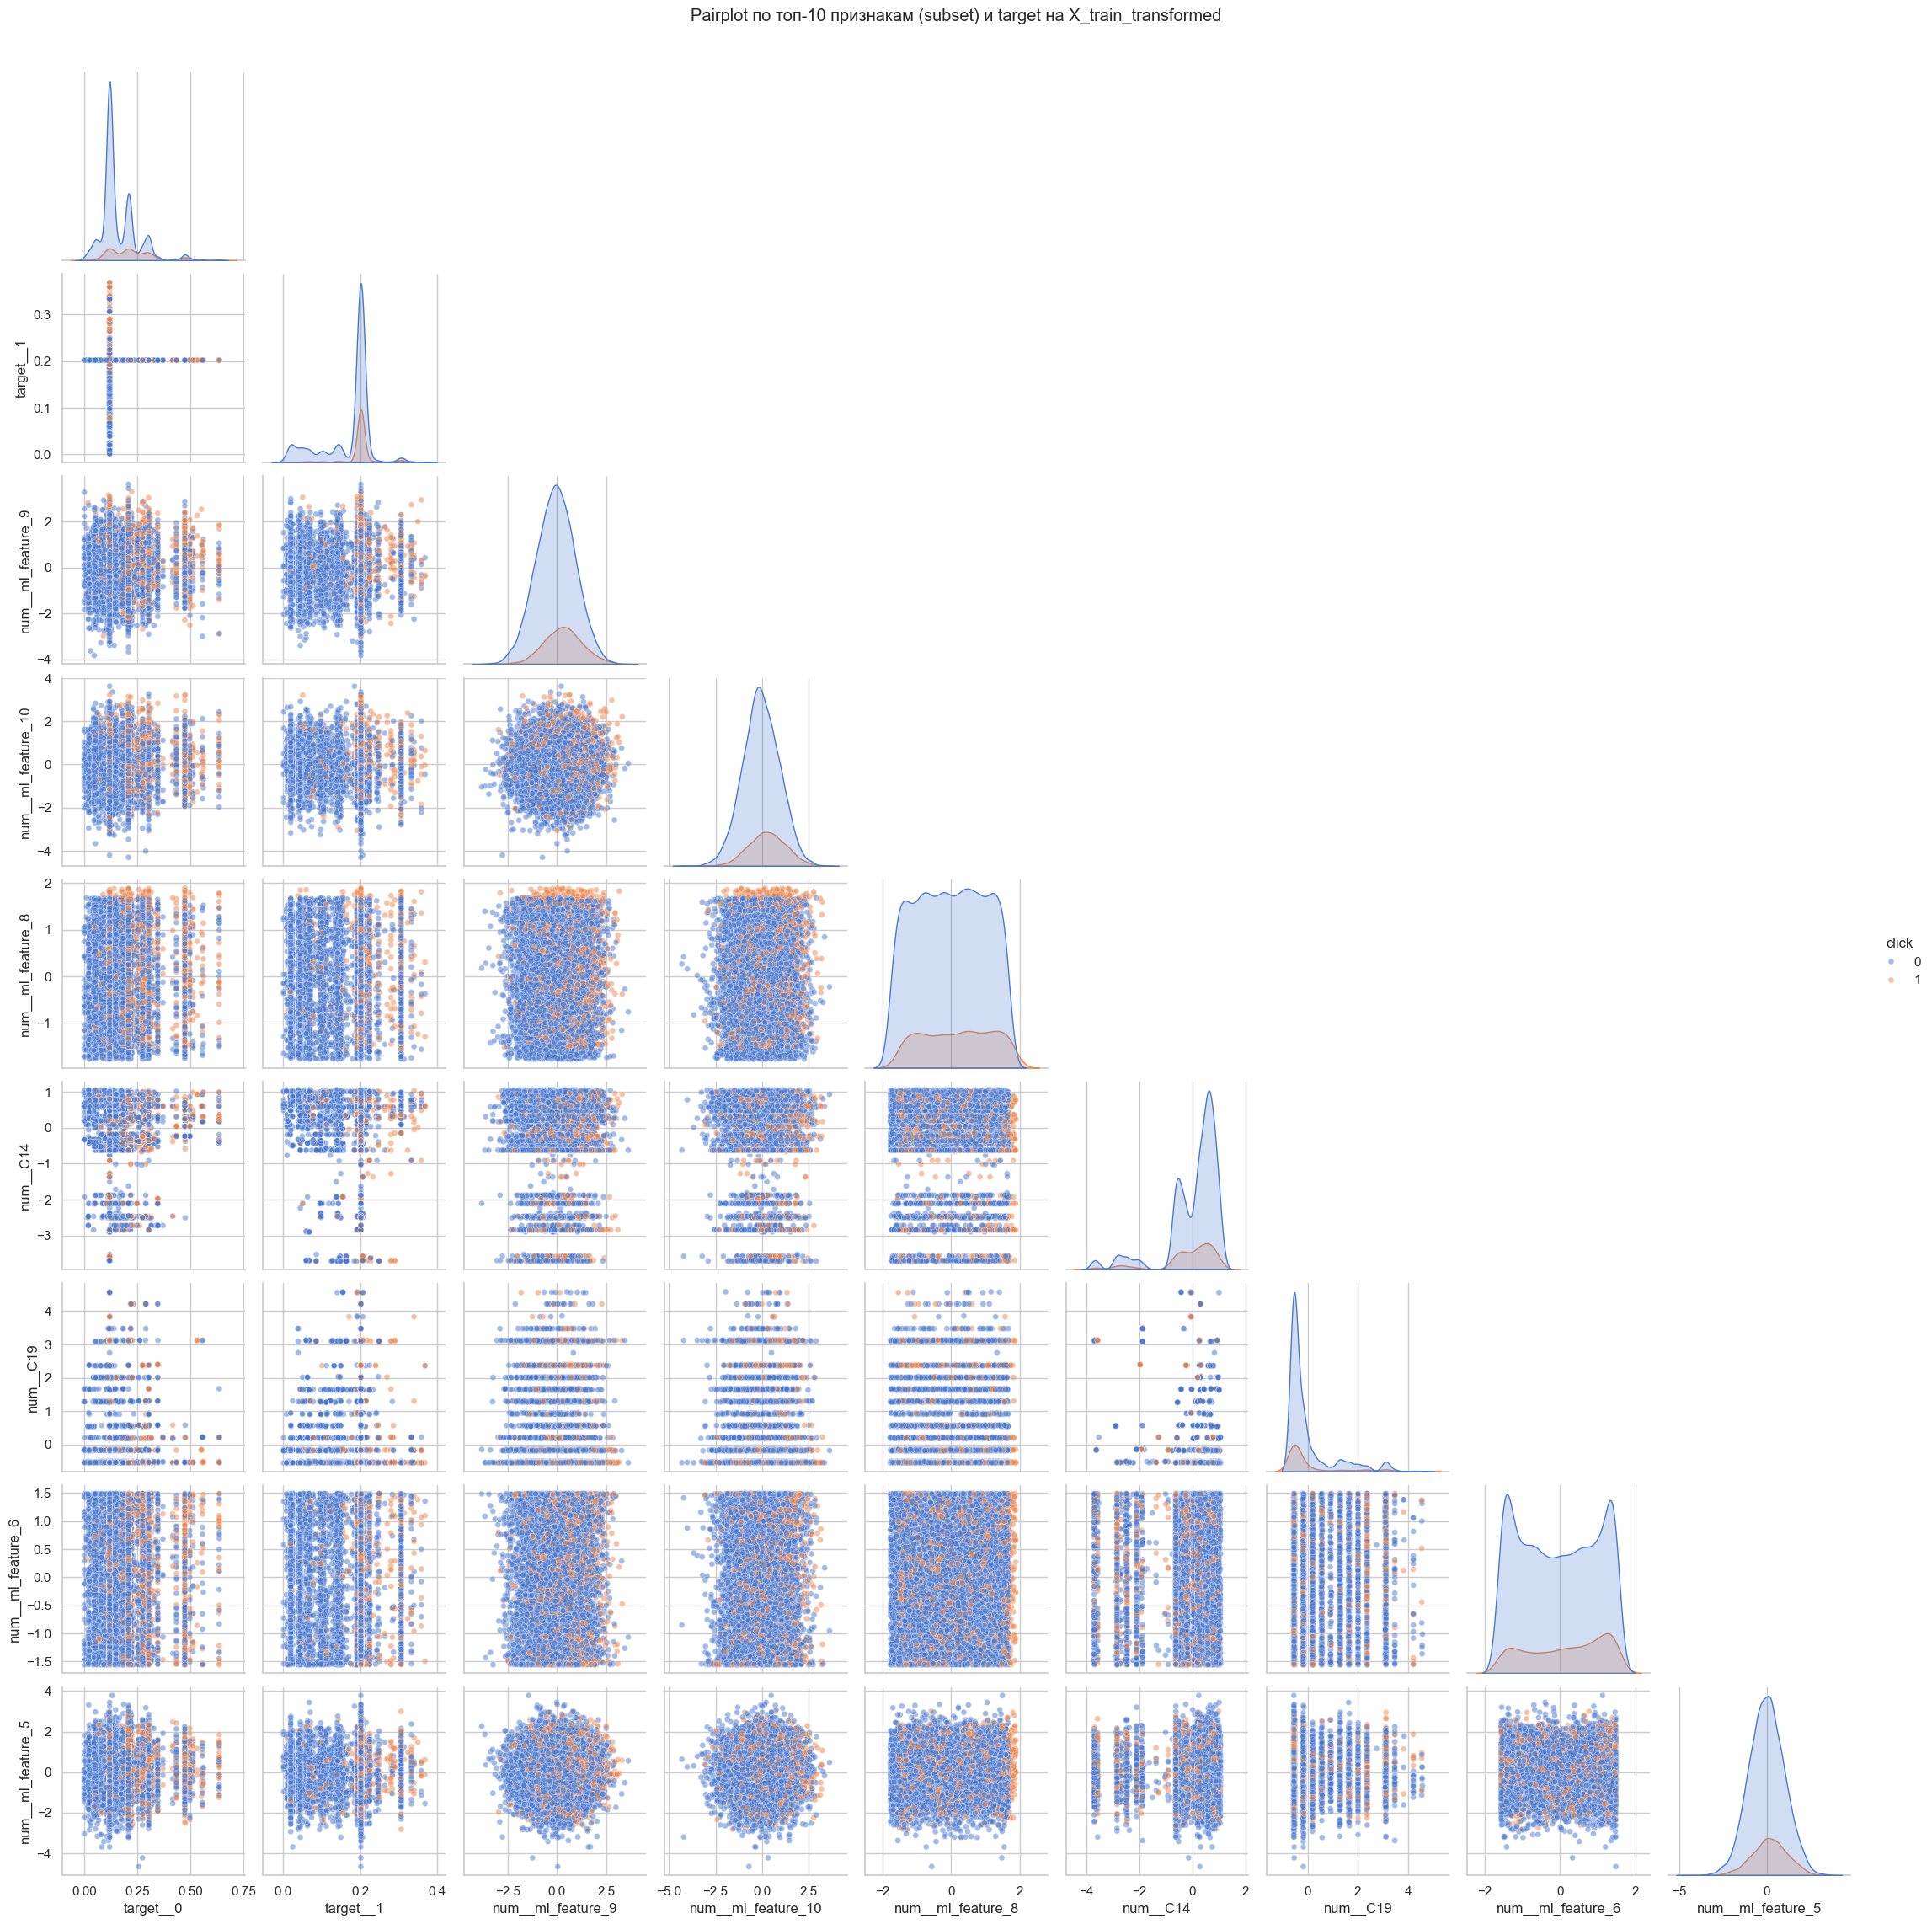

In [38]:
top_10_features = [f[0] for f in top_features_corr[:10]]

# Трансформированные (и уже отобранные) признаки с названиями
X_train_transformed = pd.DataFrame(
    X_train_selected,
    columns=selected_feature_names,
    index=getattr(y_train, 'index', None)
)

# Ограничиваем объём данных для скорости отрисовки
sample_frac = 0.25 if len(X_train_transformed) > 10000 else 1.0
X_vis = X_train_transformed[top_10_features].sample(
    frac=sample_frac, random_state=RANDOM_STATE
)

# target для выбранных индексов
if hasattr(y_train, 'loc'):
    y_vis = y_train.loc[X_vis.index]
else:
    y_vis = pd.Series(y_train, index=X_train_transformed.index).loc[X_vis.index]

sns.set(style='whitegrid', palette='muted', font_scale=1.0)
pp = sns.pairplot(
    pd.concat([X_vis, y_vis.rename('click')], axis=1),
    hue='click',
    corner=True,
    vars=top_10_features,
    plot_kws={'alpha': 0.5, 's': 25},
    diag_kind='kde',
)
pp.fig.suptitle('Pairplot по топ-10 признакам (subset) и target на X_train_transformed', y=1.02)
plt.show()


На графика можно заметить, что классы часто отделимы с помощью полиномиальной кривой, а также имеют более сложные зависимости. Полиномиальное ядро уже отобрано, другими ядрами станут `linear` и `rbf`, который справляется с сложными нелинейными зависимостями.

Составим усложненную сетку подбора гиперпараметров и отберем лучшую модель SVM.

In [ ]:
param_grid_SVM_complex = [
    {
        "model__kernel": ["poly"],
        "model__C": [0.1, 1, 10],
        "model__gamma": ["scale"],
        "model__degree": [2, 3]
    },
    {
        "model__kernel": ["rbf"],
        "model__C": [0.1, 1, 10],
        "model__gamma": ["scale"]
    }
]


In [ ]:
svm_grid_complex = GridSearchCV(
    estimator=Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('feature_selector', feature_selector),
        ('model', SVC(probability=True, random_state=RANDOM_STATE)),
    ]),
    param_grid=param_grid_SVM_complex, 
    cv=3, 
    scoring='average_precision', 
    n_jobs=-1, 
    verbose=0  # Снизим verbose для сложной сетки
)

svm_grid_complex.fit(X_train, y_train)

print(f"\nЛучшие параметры для SVM (расширённая сетка): {svm_grid_complex.best_params_}")
print(f"Лучший score для SVM (расширённая сетка): {svm_grid_complex.best_score_:.4f}")


Лучшие параметры для SVM (расширённая сетка): {'C': 10, 'degree': 3, 'gamma': 'scale', 'kernel': 'poly'}
Лучший score для SVM (расширённая сетка): 0.3989


### 7.3. Объединённая таблица топ-10 моделей

In [46]:
# Подготовка данных для LogisticRegression
logreg_results = []
for i, (params, mean_score, std_score) in enumerate(zip(
    logreg_grid.cv_results_['params'],
    logreg_grid.cv_results_['mean_test_score'],
    logreg_grid.cv_results_['std_test_score']
)):
    logreg_results.append({
        'Модель': 'LogisticRegression',
        'Параметры': str(params),
        'Mean Score': mean_score,
        'Std Score': std_score,
        'Итоговый Score': mean_score
    })

# Подготовка данных для SVM (расширённая сетка)
svm_results = []
for i, (params, mean_score, std_score) in enumerate(zip(
    svm_grid_complex.cv_results_['params'],
    svm_grid_complex.cv_results_['mean_test_score'],
    svm_grid_complex.cv_results_['std_test_score']
)):
    svm_results.append({
        'Модель': 'SVM',
        'Параметры': str(params),
        'Mean Score': mean_score,
        'Std Score': std_score,
        'Итоговый Score': mean_score
    })

# Объединение результатов
all_results = pd.DataFrame(logreg_results + svm_results)

# Сортировка по Итоговому Score и выбор топ-10
top_10_results = all_results.nlargest(10, 'Итоговый Score').reset_index(drop=True)

# Форматирование для удобства
display_results = top_10_results.copy()
display_results['Mean Score'] = display_results['Mean Score'].apply(lambda x: f'{x:.6f}')
display_results['Std Score'] = display_results['Std Score'].apply(lambda x: f'{x:.6f}')
display_results['Итоговый Score'] = display_results['Итоговый Score'].apply(lambda x: f'{x:.6f}')

display(display_results)

,Модель,Параметры,Mean Score,Std Score,Итоговый Score
0,LogisticRegression,"{'C': 100, 'max_iter': 1000, 'penalty': 'l1', ...",0.437926,0.018847,0.437926
1,LogisticRegression,"{'C': 100, 'max_iter': 2000, 'penalty': 'l1', ...",0.437926,0.018847,0.437926
2,LogisticRegression,"{'C': 10, 'max_iter': 1000, 'penalty': 'l1', '...",0.437813,0.018749,0.437813
3,LogisticRegression,"{'C': 10, 'max_iter': 2000, 'penalty': 'l1', '...",0.437813,0.018749,0.437813
4,LogisticRegression,"{'C': 100, 'max_iter': 1000, 'penalty': 'l1', ...",0.437809,0.018691,0.437809
5,LogisticRegression,"{'C': 100, 'max_iter': 2000, 'penalty': 'l1', ...",0.437809,0.018691,0.437809
6,LogisticRegression,"{'C': 100, 'l1_ratio': 0.9, 'max_iter': 1000, ...",0.437802,0.018682,0.437802
7,LogisticRegression,"{'C': 100, 'l1_ratio': 0.9, 'max_iter': 2000, ...",0.437802,0.018682,0.437802
8,LogisticRegression,"{'C': 100, 'l1_ratio': 0.5, 'max_iter': 1000, ...",0.437802,0.018683,0.437802
9,LogisticRegression,"{'C': 100, 'l1_ratio': 0.5, 'max_iter': 2000, ...",0.437802,0.018683,0.437802


По итогам сравнения моделей, лучшей оказалась модель логистической регрессии с параметрами `{'C': 100, 'max_iter': 1000, 'penalty': 'l1', 'solver': 'liblinear', 'tol': 0.001}` и значением метрики PR-AUC равной `0.4379`, что является хорошим результатом, так как выше предсказаний базового класса примерно в 2.5 раза (DummyClassifier имеет значение PR-AUC `0.17`). Такое значение метрики является некритичным для маркетинговой сферы.

---

## 8. Подготовка финальной модели

### 8.1. Обучение финальной модели и расчет метрик

In [ ]:
# Проверим интервал предсказаний модели на кросс-валидации
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

best_model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('feature_selector', feature_selector),
    ('model', LogisticRegression(C=100, max_iter=1000, penalty='l1', solver='liblinear', tol=0.001)),
])
best_model_pipeline.fit(X_train, y_train)

cv_results = cross_validate(
    Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('feature_selector', feature_selector),
        ('model', LogisticRegression(C=100, max_iter=1000, penalty='l1', solver='liblinear', tol=0.001)),
    ]),
    X_train,
    y_train,
    cv=cv,
    scoring='average_precision',
    return_train_score=False
)

pr_auc_scores = cv_results['test_score']
min_pr_auc = pr_auc_scores.min()
max_pr_auc = pr_auc_scores.max()

print(f"Минимальный PR-AUC на кросс-валидации: {min_pr_auc:.4f}")
print(f"Максимальный PR-AUC на кросс-валидации: {max_pr_auc:.4f}")

Минимальный PR-AUC на кросс-валидации: 0.4245
Максимальный PR-AUC на кросс-валидации: 0.4484


In [ ]:
# Подсчет метрик на тестовой выборке
y_pred_proba = best_model_pipeline.predict_proba(X_test)[:, 1]

log_loss = log_loss(y_test, y_pred_proba)
pr_auc = average_precision_score(y_test, y_pred_proba)
roc_auc = roc_auc_score(y_test, y_pred_proba)
brier_score = brier_score_loss(y_test, y_pred_proba)

print(f"Log Loss: {log_loss:.4f}")
print(f"PR-AUC: {pr_auc:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"Brier Score: {brier_score:.4f}")


Log Loss: 0.4030
PR-AUC: 0.3976
ROC-AUC: 0.7443
Brier Score: 0.1251


PR-AUC на тестовой выборке снизился до `0.3977`. Это немного ниже минимального диапазона, который был на кросс-валидации (`0.4245`) на одном из фолдов, что указывает на небольшое переобучение модели.

Метрика все еще больше базовой модели примерно в 2.2 раза, а небольшое падание абсолютно нормально для сферы маркетинга, где данные содержат много шума.

Оценка Бриера, точность предсказанных вероятностей, отражает хорошую калибровку модели. 

---

### 8.2. Анализ весов модели

In [ ]:
model_step = best_model_pipeline.named_steps['model']
coefs = np.asarray(model_step.coef_).ravel()
intercept = float(np.asarray(model_step.intercept_).ravel()[0])

weights_df = pd.DataFrame({
    'feature': selected_feature_names,
    'coef': coefs,
    'abs_coef': np.abs(coefs),
})

# L1-регуляризация даёт разреженность: многие коэффициенты становятся ровно 0.
nonzero_df = (
    weights_df[weights_df['coef'] != 0]
    .sort_values('abs_coef', ascending=False)
)

print(f"Ненулевых коэффициентов: {len(nonzero_df)} из {len(weights_df)}")

# Топ-10 с направлением влияния
top_k = 10
nonzero_df.head(top_k)

Ненулевых коэффициентов: 16 из 16


,feature,coef,abs_coef
15,target__1,9.491380,9.491380
14,target__0,5.935088,5.935088
7,onehot__C15_120,-1.772775,1.772775
11,onehot__C16_480,0.989804,0.989804
13,onehot__C18_1,-0.581668,0.581668
5,num__ml_feature_9,0.417499,0.417499
6,num__ml_feature_10,0.352457,0.352457
8,onehot__C15_300,0.225039,0.225039
4,num__ml_feature_8,0.208454,0.208454
9,onehot__C15_320,0.194576,0.194576


Модель выделила три наиболее важных признака: `app_id` (`target__1`), `site_id` (`target__0`), `C15`. Это означает, что вероятность клика на рекламу зависит от сайта размещения, рекламируемого приложения и признака `C15`, который может описывать параметры баннера, пользователя или аукциона.

---

## 9. Калибровка модели

In [50]:
def calibration_errors(y_true, y_prob, n_bins=10):
    """Вычисляет ECE и MCE"""
    bins = np.linspace(0, 1, n_bins + 1)
    binids = np.digitize(y_prob, bins) - 1
    ece = 0.0
    mce = 0.0
    for i in range(n_bins):
        mask = binids == i
        if np.any(mask):
            avg_prob = y_prob[mask].mean()
            avg_true = y_true[mask].mean()
            bin_ece = np.abs(avg_prob - avg_true) * (mask.sum() / len(y_true))
            ece += bin_ece
            mce = max(mce, np.abs(avg_prob - avg_true))
    return ece, mce

In [ ]:
# Калибровка на независимой выборке
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# Выбираем сигмоиду, т.к. на графике калибрационной кривой логистическая регрессия не имеет сложных искажений
calibrated_model = CalibratedClassifierCV(estimator=best_model_pipeline, method='sigmoid', cv=inner_cv)
calibrated_model.fit(X_train, y_train)

# Предсказания вероятностей для тестовой выборки (некалиброванные)
y_pred_proba_uncalibrated = best_model_pipeline.predict_proba(X_test)[:, 1]
brier_uncalibrated = brier_score_loss(y_test, y_pred_proba_uncalibrated)
ece_uncalibrated, mce_uncalibrated = calibration_errors(y_test, y_pred_proba_uncalibrated)

print(f"Оценка Бриера (некалиброванная модель): {brier_uncalibrated:.5f}")
print(f"ECE (некалиброванная модель): {ece_uncalibrated:.5f}")
print(f"MCE (некалиброванная модель): {mce_uncalibrated:.5f}")

# Получаем откалиброванные вероятности на тесте
y_pred_proba_calibrated = calibrated_model.predict_proba(X_test)[:, 1]
brier_calibrated = brier_score_loss(y_test, y_pred_proba_calibrated)
ece_calibrated, mce_calibrated = calibration_errors(y_test, y_pred_proba_calibrated)

print(f"Оценка Бриера (калиброванная модель): {brier_calibrated:.5f}")
print(f"ECE (калиброванная модель): {ece_calibrated:.5f}")
print(f"MCE (калиброванная модель): {mce_calibrated:.5f}")




Оценка Бриера (некалиброванная модель): 0.12514
ECE (некалиброванная модель): 0.01288
MCE (некалиброванная модель): 0.12053
Оценка Бриера (калиброванная модель): 0.12514
ECE (калиброванная модель): 0.01258
MCE (калиброванная модель): 0.12034


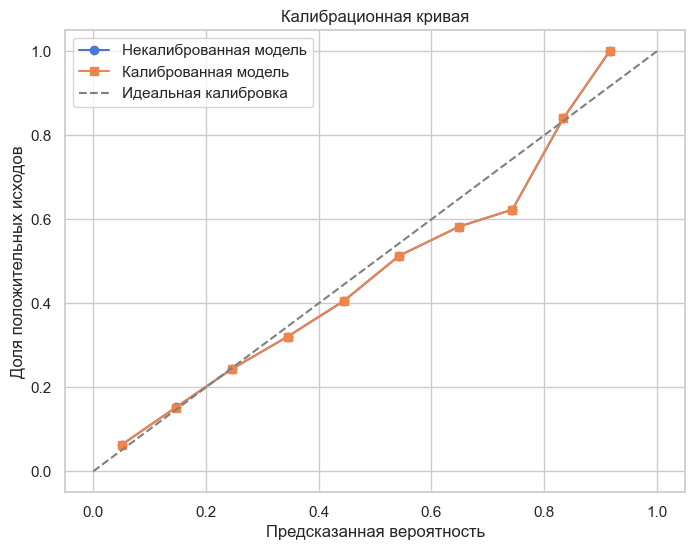

In [52]:
# Получаем калибрационные кривые
prob_true_uncal, prob_pred_uncal = calibration_curve(y_test, y_pred_proba_uncalibrated, n_bins=10, strategy='uniform')
prob_true_cal, prob_pred_cal = calibration_curve(y_test, y_pred_proba_calibrated, n_bins=10, strategy='uniform')

plt.figure(figsize=(8, 6))
plt.plot(prob_pred_uncal, prob_true_uncal, marker='o', label="Некалиброванная модель")
plt.plot(prob_pred_cal, prob_true_cal, marker='s', label="Калиброванная модель")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Идеальная калибровка')
plt.xlabel("Предсказанная вероятность")
plt.ylabel("Доля положительных исходов")
plt.title("Калибрационная кривая")
plt.legend()
plt.grid(True)
plt.show()

Калибровка практически не повлияла на предсказания лучшей модели. Это объясняется тем, что логистическая регрессия хорошо откалибрована из-за минимизации функции Log Loss, которая заставляет модель настраивать выходы под эмпирические вероятность. 

Несмотря на агрессивный метод регуляризации (Lasso), признаки были отобраны так, что модель не обнулила ни один из них. Это также уменьшило разницу с калибровочной моделью.

---

## 11. Финальный отчет и выводы

### 11.1. Базовая и финальная модель

**Базовая модель (`DummyClassifier`, `strategy='prior'`)**:
- `Log Loss`: **0.4592**
- `PR-AUC`: **0.1721**

Базовая модель фактически предсказывает вероятность по доле класса и задает нижнюю границу качества.

**Финальная модель (`LogisticRegression`)**:
- Параметры: `C=100`, `penalty='l1'`, `solver='liblinear'`, `max_iter=1000`, `tol=0.001`
- Признаки: 16 отобранных признаков после препроцессинга и `SequentialFeatureSelector`
- Лучший результат на кросс-валидации (`PR-AUC`): **0.4379**
- Диапазон `PR-AUC` по фолдам: **0.4245 - 0.4484**
- Тестовые метрики (до калибровки):
  - `Log Loss`: **0.4030**
  - `PR-AUC`: **0.3976**
  - `ROC-AUC`: **0.7443**
  - `Brier Score`: **0.1251**

---

### 11.2. Метрики до и после калибровки

Калибровка выполнялась через `CalibratedClassifierCV(method='sigmoid', cv=3)`.

**До калибровки**:
- `Brier`: **0.12514**
- `ECE`: **0.01288**
- `MCE`: **0.12053**

**После калибровки**:
- `Brier`: **0.12514**
- `ECE`: **0.01258**
- `MCE`: **0.12034**

**Вывод по калибровке**: улучшение минимальное. Модель уже была хорошо откалибрована, что ожидаемо для логистической регрессии, оптимизирующей log loss.

---

### 11.3. Топ-5 наиболее важных признаков (по модулю коэффициента)

По `|coef|` финальной модели:
1. `target__1` (`app_id`) — **9.4914** (положительное влияние)
2. `target__0` (`site_id`) — **5.9351** (положительное влияние)
3. `onehot__C15_120` (`C15=120`) — **1.7728** (отрицательное влияние)
4. `onehot__C16_480` (`C16=480`) — **0.9898** (положительное влияние)
5. `onehot__C18_1` (`C18=1`) — **0.5817** по модулю, знак коэффициента отрицательный (`-0.5817`)

**Интерпретация**:
- На вероятность клика сильнее всего влияют идентификаторы площадки и приложения (`site_id`, `app_id`) после target encoding.
- Отдельные категории баннерных/аукционных признаков (`C15`, `C16`, `C18`) заметно сдвигают лог-отношение шансов клика вверх или вниз.
- Модель фиксирует выраженные сегментные различия: где и для какого приложения показывается реклама, важнее большинства непрерывных `ml_feature_*`.

---

### 11.4. Ответы на ключевые вопросы

**Улучшилось ли качество модели по сравнению с базовой?**
- Да, существенно. По `PR-AUC` рост с **0.1721** до **0.3976** на тесте (примерно в 2.3 раза).
- По `Log Loss` также лучше: **0.4592 -> 0.4030**.

**Какие признаки больше всего влияют на вероятность клика?**
- В первую очередь `app_id` и `site_id` (через target encoding), далее категории `C15`, `C16`, `C18`.

**Насколько хорошо модель откалибрована?**
- Хорошо: низкий `ECE` (~0.013) и стабильный `Brier` (~0.125).
- Дополнительная сигмоидная калибровка дает только небольшое улучшение (`ECE`/`MCE`), без эффекта по `Brier`.

**Готова ли модель к использованию в продакшене?**
- **Да**: модель заметно лучше baseline и даёт адекватные вероятности.

---

### 11.5. Рекомендации по улучшению

**Расширение фичей**: признаки частоты/давности показов, пользовательские и контекстные агрегаты, взаимодействия (`site_id x app_id`, `hour x device_type` и т.д.).

---

## 12. Сохранение модели для продакшена

Для продакшена сохраняем целостный обучающий пайплайн (предобработка + выбор отобранных признаков + модель), а также отдельный файл с индексами признаков отбора:

- `best_model_pipeline.joblib` — единый пайплайн обучения (preprocessor + feature_selector + model)
- `selected_indices.joblib` — индексы признаков после отбора
- `calibrated_model.joblib` — калиброванная версия итогового пайплайна
- метаданные (`target`, `metrics`, `model_params`) — для мониторинга и воспроизводимости

Ниже код формирует каталог артефактов, сохраняет все объекты и показывает пример загрузки и предсказания на новых данных.


In [ ]:
# Метаданные модели
model_metadata = {
    'target': 'click',
    'model_type': 'LogisticRegression',
    'model_params': best_model_pipeline.named_steps['model'].get_params(),
    'selected_feature_names': list(selected_feature_names),
    'n_selected_features': int(len(selected_feature_names)),
    'test_metrics_uncalibrated': {
        'log_loss': float(log_loss),
        'pr_auc': float(pr_auc),
        'roc_auc': float(roc_auc),
        'brier_score': float(brier_score),
    },
    'calibration_metrics': {
        'uncalibrated': {
            'brier': float(brier_uncalibrated),
            'ece': float(ece_uncalibrated),
            'mce': float(mce_uncalibrated),
        },
        'calibrated': {
            'brier': float(brier_calibrated),
            'ece': float(ece_calibrated),
            'mce': float(mce_calibrated),
        },
    },
}

# Сохранение артефактов
joblib.dump(best_model_pipeline, 'best_model_pipeline.joblib')
joblib.dump(selected_indices, 'selected_indices.joblib')
joblib.dump(calibrated_model, 'calibrated_model.joblib')

# Пример загрузки и инференса
loaded_best_model_pipeline = joblib.load('best_model_pipeline.joblib')
loaded_selected_indices = joblib.load('selected_indices.joblib')
loaded_calibrated_model = joblib.load('calibrated_model.joblib')

# Берем 3 примера из теста и прогнозируем вероятности клика
sample_X = X_test.head(3).copy()

sample_proba_uncal = loaded_best_model_pipeline.predict_proba(sample_X)[:, 1]
sample_proba_cal = loaded_calibrated_model.predict_proba(sample_X)[:, 1]

inference_example = pd.DataFrame({
    'pred_proba_uncalibrated': sample_proba_uncal,
    'pred_proba_calibrated': sample_proba_cal,
})

display(inference_example)


,pred_proba_uncalibrated,pred_proba_calibrated
0,0.408750,0.408506
1,0.170547,0.170237
2,0.064515,0.064374


Модель успешно сохранена и работает после загрузки и запуска.

---